# Task 1 — Multi-Class Classification Pipeline (Iris)
**Datheon Machine Learning & Data Science Internship · Difficulty: beginner**

**Goal.** Build an end-to-end classification pipeline that predicts the species of an iris flower from four measurements.

| Item | Detail |
|---|---|
| Dataset | Iris (150 flowers, 3 species) — `data/iris.csv` from the seaborn-data repository, the link given in the official task pack |
| Models | Logistic Regression and Decision Tree |
| Preprocessing | `StandardScaler` inside a scikit-learn `Pipeline` (no leakage) |
| Split | 80 % train / 20 % test, stratified |
| Metrics | Accuracy, precision, recall, F1-score, confusion matrix |
| Deliverable | This notebook, `results/*.png`, `models/*.joblib`, `results/metrics.json` |

**Notebook map:** 1 Imports → 2 Load → 3 Inspect → 4 Clean → 5 EDA → 6 Visualise → 7 Features/target → 8 Split → 9 Scaling + pipelines → 10 Cross-validation → 11 Train & evaluate → 12 Confusion matrices → 13 Reports → 14 Model comparison → 15 Decision tree & boundary → 16 Prediction function → 17 Save → 18 Conclusions

## 1. Import libraries

In [1]:
import sys, json, warnings
from pathlib import Path

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent                      # repository root (notebook is run from its own task folder)
sys.path.insert(0, str(ROOT / "src"))         # makes the shared `datheon_ml` helpers importable

import inspect
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from sklearn.tree import plot_tree

from datheon_ml.iris import FEATURES, TARGET, load_iris, build_pipelines, predict_species

sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42
DATA_PATH, RESULTS, MODELS = Path("data/iris.csv"), Path("results"), Path("models")
RESULTS.mkdir(exist_ok=True); MODELS.mkdir(exist_ok=True)
print("Libraries imported. Random state:", RANDOM_STATE)

Libraries imported. Random state: 42


## 2. Load the dataset

In [2]:
df = load_iris(DATA_PATH)
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Data inspection
Check the number of rows/columns, data types, summary statistics and class balance.

In [3]:
print("Shape (rows, columns):", df.shape)
print()
df.info()

Shape (rows, columns): (150, 5)

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [4]:
display(df.describe().round(3))
print("Samples per species:")
display(df[TARGET].value_counts())

,sepal_length,sepal_width,petal_length,petal_width
count,150.000,150.000,150.000,150.000
mean,5.843,3.057,3.758,1.199
std,0.828,0.436,1.765,0.762
min,4.300,2.000,1.000,0.100
25%,5.100,2.800,1.600,0.300
50%,5.800,3.000,4.350,1.300
75%,6.400,3.300,5.100,1.800
max,7.900,4.400,6.900,2.500


Samples per species:


species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

## 4. Data cleaning
Check missing values and exact duplicate rows.

In [5]:
print("Missing values per column:")
display(df.isna().sum())
n_dup = int(df.duplicated().sum())
print("Duplicate rows:", n_dup)
display(df[df.duplicated(keep=False)])

Missing values per column:


sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows: 1


,sepal_length,sepal_width,petal_length,petal_width,species
101,5.8,2.7,5.1,1.9,virginica
142,5.8,2.7,5.1,1.9,virginica


One exact duplicate pair exists in this version of Iris. Duplicate rows can end up on both sides of the train/test split and slightly inflate scores, so the repeated row is removed. There are no missing values.

In [6]:
rows_before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {rows_before} | rows after removing duplicates: {len(df)}")

Rows before: 150 | rows after removing duplicates: 149


## 5. Exploratory data analysis

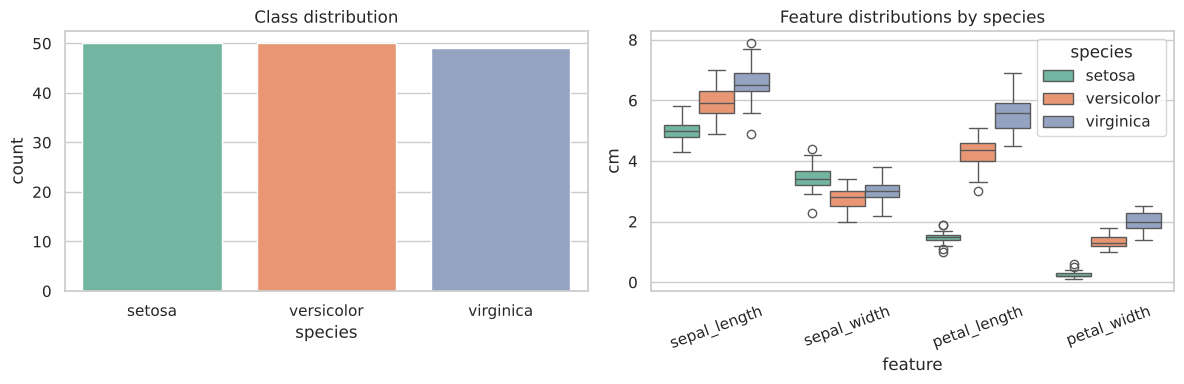

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x=TARGET, hue=TARGET, palette="Set2", legend=False, ax=axes[0])
axes[0].set_title("Class distribution")
df_melt = df.melt(id_vars=TARGET, value_vars=FEATURES, var_name="feature", value_name="cm")
sns.boxplot(data=df_melt, x="feature", y="cm", hue=TARGET, palette="Set2", ax=axes[1])
axes[1].set_title("Feature distributions by species")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

In [8]:
display(df.groupby(TARGET)[FEATURES].mean().round(2))

,sepal_length,sepal_width,petal_length,petal_width
species,,,,
setosa,5.01,3.43,1.46,0.25
versicolor,5.94,2.77,4.26,1.33
virginica,6.60,2.98,5.56,2.03


**Observation.** Setosa is clearly separated by its small petals. Versicolor and virginica overlap a little, so they are the pair the models can confuse.

## 6. Visualisation — pairplot and correlation heatmap

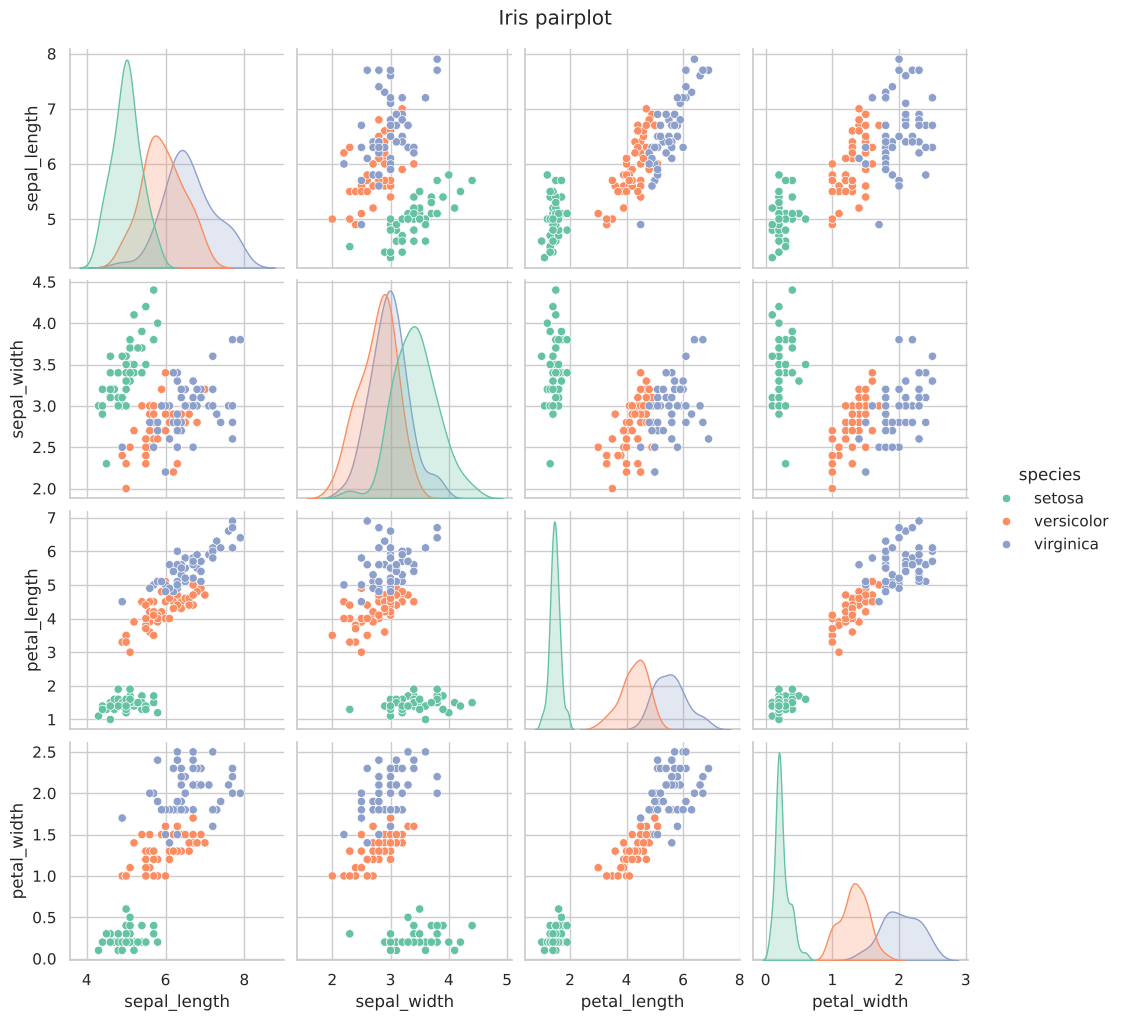

In [9]:
pair = sns.pairplot(df, hue=TARGET, palette="Set2", diag_kind="kde", corner=False)
pair.figure.suptitle("Iris pairplot", y=1.02)
pair.savefig(RESULTS / "pairplot.png", dpi=150, bbox_inches="tight")
plt.show()

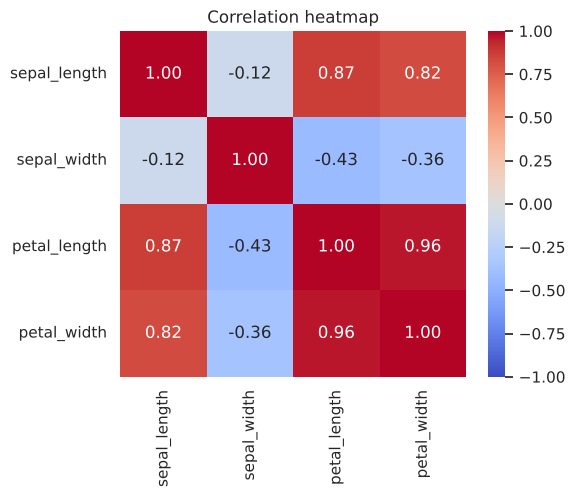

In [10]:
plt.figure(figsize=(6, 5))
corr = df[FEATURES].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Correlation heatmap")
plt.tight_layout()
plt.savefig(RESULTS / "correlation_heatmap.png", dpi=150)
plt.show()

Petal length and petal width are very strongly correlated (about 0.96), and both relate strongly to the species.

## 7. Feature selection — separate inputs and target

In [11]:
X = df[FEATURES]
y = df[TARGET]
print("X shape:", X.shape, "| y shape:", y.shape)
print("Classes:", sorted(y.unique()))

X shape: (149, 4) | y shape: (149,)
Classes: ['setosa', 'versicolor', 'virginica']


## 8. Train / test split (80 % / 20 %)
`stratify=y` keeps the species proportions equal in both sets.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Test class counts:", y_test.value_counts().to_dict())

Train: (119, 4) | Test: (30, 4)
Test class counts: {'versicolor': 10, 'virginica': 10, 'setosa': 10}


## 9. Feature scaling and model pipelines
`StandardScaler` rescales every feature to mean 0 and standard deviation 1. The scaler is placed **inside** a `Pipeline`, so it is fitted on training data only and just applied to the test data — this prevents data leakage.

Models: **Logistic Regression** (linear, probabilistic) and **Decision Tree** (`max_depth=3`, easy to read and less prone to over-fitting).

In [13]:
models = build_pipelines(RANDOM_STATE)
for name, pipe in models.items():
    print(name, "->", [step for step, _ in pipe.steps])

Logistic Regression -> ['scaler', 'model']
Decision Tree -> ['scaler', 'model']


In [14]:
print(inspect.getsource(build_pipelines))      # the exact model definitions (source lives in src/datheon_ml/iris.py)

def build_pipelines(random_state: int = 42) -> dict[str, Pipeline]:
    """Return the two required models, each wrapped with StandardScaler.

    Using a Pipeline means the scaler is fitted on training data only, so no
    information from the test set leaks into preprocessing.
    """
    return {
        "Logistic Regression": Pipeline(
            [
                ("scaler", StandardScaler()),
                ("model", LogisticRegression(max_iter=1000, random_state=random_state)),
            ]
        ),
        "Decision Tree": Pipeline(
            [
                ("scaler", StandardScaler()),
                ("model", DecisionTreeClassifier(max_depth=3, random_state=random_state)),
            ]
        ),
    }



## 10. Cross-validation (stability check on the training data only)

In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_results = {}
for name, pipe in models.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
    cv_results[name] = (scores.mean(), scores.std())
    print(f"{name:<22} 5-fold accuracy: {scores.mean():.4f} ± {scores.std():.4f}")

Logistic Regression    5-fold accuracy: 0.9656 ± 0.0506
Decision Tree          5-fold accuracy: 0.9319 ± 0.0591


## 11. Train both models and evaluate on the unseen test set

In [16]:
rows, preds = [], {}
for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    preds[name] = y_pred
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "CV accuracy (mean)": cv_results[name][0],
    })
metrics_df = pd.DataFrame(rows).set_index("Model").round(4)
metrics_df

,Accuracy,Precision (macro),Recall (macro),F1 (macro),CV accuracy (mean)
Model,,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9656
Decision Tree,0.9667,0.9697,0.9667,0.9666,0.9319


## 12. Confusion matrices

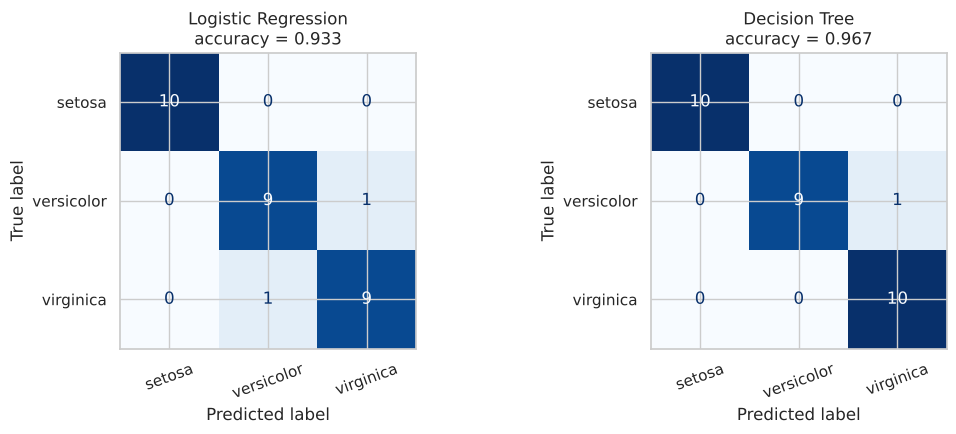

In [17]:
labels = sorted(y.unique())
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, y_pred) in zip(axes, preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred, labels=labels), display_labels=labels).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_title(f"{name}\naccuracy = {accuracy_score(y_test, y_pred):.3f}")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(RESULTS / "confusion_matrix.png", dpi=150)
plt.show()

## 13. Classification reports (precision, recall, F1 per class)

In [18]:
for name, y_pred in preds.items():
    print("=" * 60); print(name); print("=" * 60)
    print(classification_report(y_test, y_pred, digits=3, zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30



## 14. Model comparison

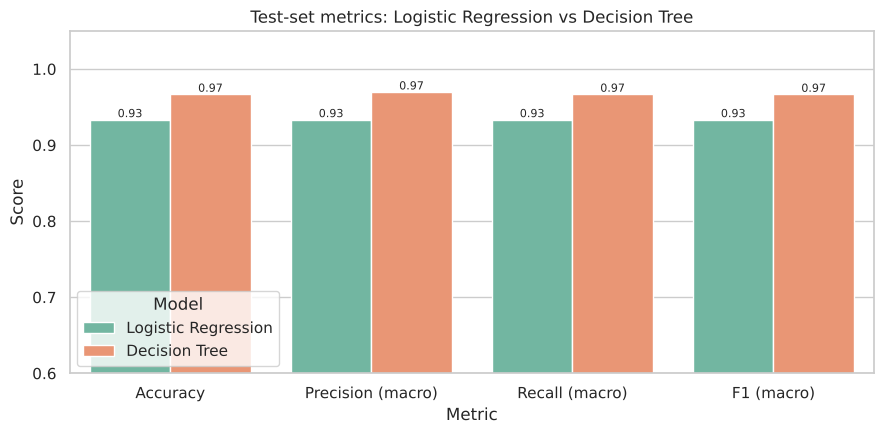

In [19]:
plot_df = metrics_df.drop(columns="CV accuracy (mean)").reset_index().melt(id_vars="Model", var_name="Metric", value_name="Score")
plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=plot_df, x="Metric", y="Score", hue="Model", palette="Set2")
ax.set_ylim(0.6, 1.05); ax.set_title("Test-set metrics: Logistic Regression vs Decision Tree")
for c in ax.containers: ax.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.savefig(RESULTS / "model_comparison.png", dpi=150)
plt.show()

With only 30 test flowers, one misclassified flower changes accuracy by 3.3 percentage points, so small differences between the two models are not statistically meaningful. The cross-validation scores above give a steadier comparison.

## 15. Decision tree structure and decision boundary

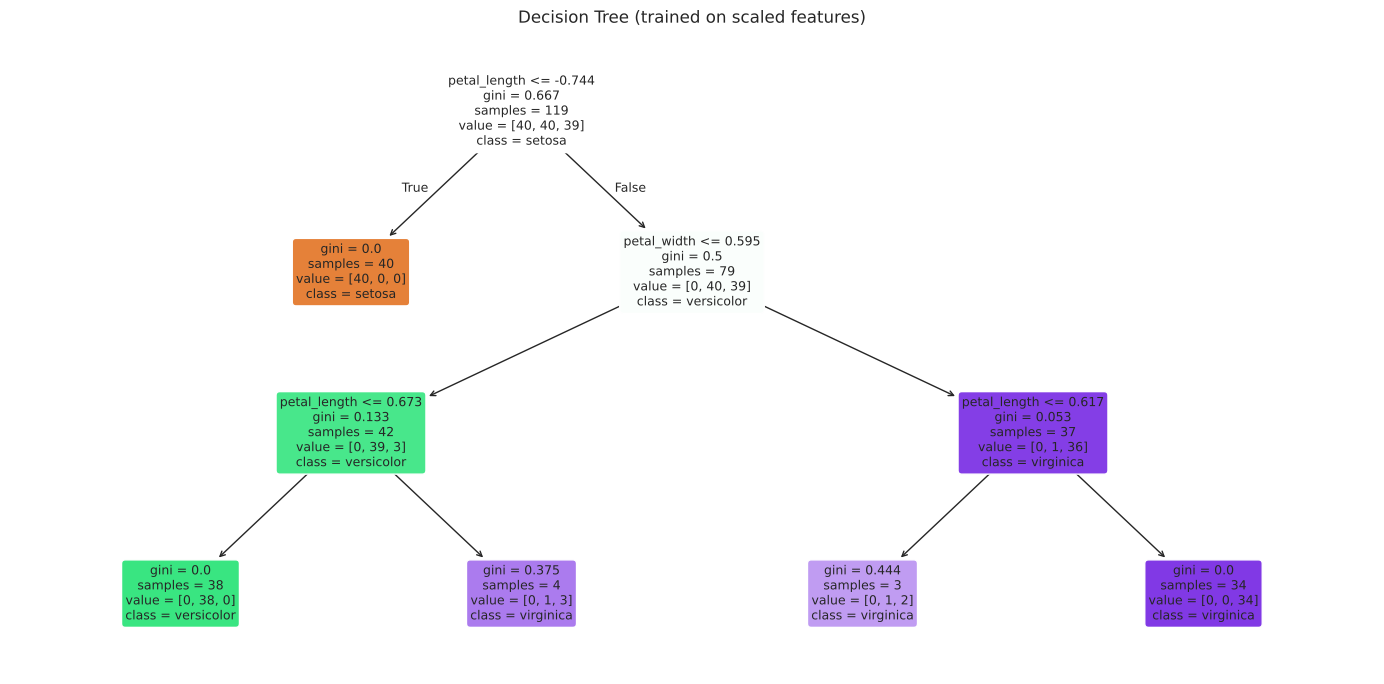

In [20]:
tree_pipe = models["Decision Tree"]
plt.figure(figsize=(14, 7))
plot_tree(tree_pipe.named_steps["model"], feature_names=FEATURES,
          class_names=list(tree_pipe.classes_), filled=True, rounded=True, fontsize=9)
plt.title("Decision Tree (trained on scaled features)")
plt.tight_layout()
plt.savefig(RESULTS / "decision_tree.png", dpi=150)
plt.show()

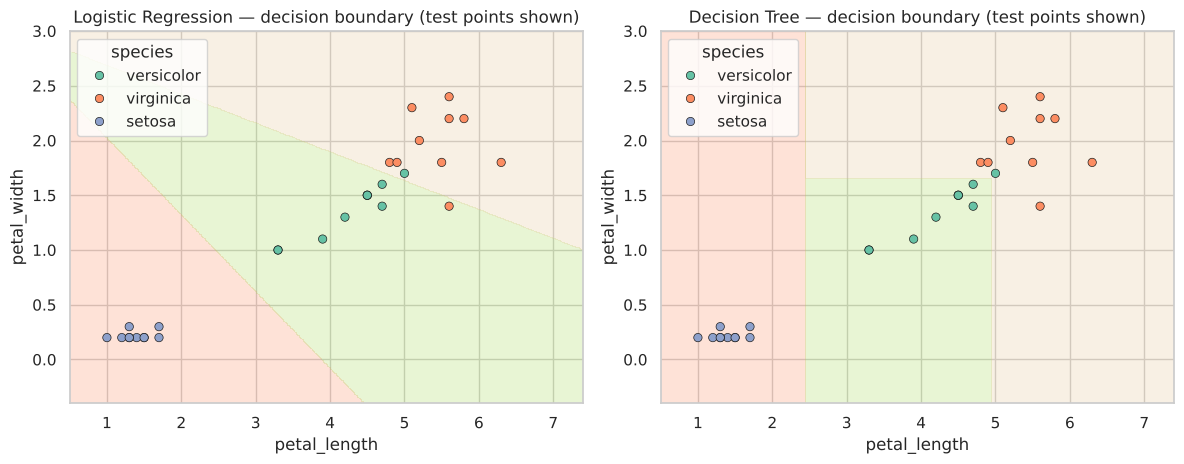

In [21]:
# Decision boundary in 2-D using the two most informative features (re-trained on those two only)
two = ["petal_length", "petal_width"]
class_to_int = {c: i for i, c in enumerate(sorted(y.unique()))}
x_min, x_max = X[two[0]].min() - 0.5, X[two[0]].max() + 0.5
y_min, y_max = X[two[1]].min() - 0.5, X[two[1]].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
grid = pd.DataFrame({two[0]: xx.ravel(), two[1]: yy.ravel()})

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, (name, pipe) in zip(axes, build_pipelines(RANDOM_STATE).items()):
    pipe.fit(X_train[two], y_train)
    zz = pd.Series(pipe.predict(grid)).map(class_to_int).to_numpy().reshape(xx.shape)
    ax.contourf(xx, yy, zz, alpha=0.25, cmap="Set2", levels=[-0.5, 0.5, 1.5, 2.5])
    sns.scatterplot(data=pd.concat([X_test[two], y_test], axis=1), x=two[0], y=two[1],
                    hue=TARGET, palette="Set2", edgecolor="k", ax=ax)
    ax.set_title(f"{name} — decision boundary (test points shown)")
plt.tight_layout()
plt.savefig(RESULTS / "decision_boundary.png", dpi=150)
plt.show()

## 16. Prediction function for a new flower

In [22]:
best_name = metrics_df["CV accuracy (mean)"].idxmax()     # chosen with cross-validation, NOT with the test set
best_model = models[best_name]
print("Model used for the prediction function:", best_name)

examples = {"small petals": (5.0, 3.4, 1.5, 0.2), "medium petals": (6.0, 2.9, 4.5, 1.4), "large petals": (6.9, 3.1, 5.8, 2.1)}
for label, vals in examples.items():
    print(label, vals, "->", predict_species(best_model, *vals))

Model used for the prediction function: Logistic Regression
small petals (5.0, 3.4, 1.5, 0.2) -> {'prediction': 'setosa', 'probabilities': {'setosa': 0.9763, 'versicolor': 0.0237, 'virginica': 0.0}}
medium petals (6.0, 2.9, 4.5, 1.4) -> {'prediction': 'versicolor', 'probabilities': {'setosa': 0.0198, 'versicolor': 0.8193, 'virginica': 0.1609}}
large petals (6.9, 3.1, 5.8, 2.1) -> {'prediction': 'virginica', 'probabilities': {'setosa': 0.0001, 'versicolor': 0.0537, 'virginica': 0.9462}}


## 17. Save the trained models and the metrics

In [23]:
joblib.dump(models["Logistic Regression"], MODELS / "logistic_regression.joblib")
joblib.dump(models["Decision Tree"], MODELS / "decision_tree.joblib")
joblib.dump(best_model, MODELS / "best_model.joblib")

summary = {"dataset_rows_after_cleaning": int(len(df)), "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
           "best_model_by_cv": best_name, "models": metrics_df.to_dict(orient="index")}
(RESULTS / "metrics.json").write_text(json.dumps(summary, indent=2))
print("Saved:", sorted(p.name for p in MODELS.iterdir()), sorted(p.name for p in RESULTS.iterdir()))

Saved: ['best_model.joblib', 'decision_tree.joblib', 'logistic_regression.joblib'] ['confusion_matrix.png', 'correlation_heatmap.png', 'decision_boundary.png', 'decision_tree.png', 'metrics.json', 'model_comparison.png', 'pairplot.png']


## 18. Conclusions

In [24]:
print(metrics_df.to_string())
print()
print(f"Best model by cross-validation: {best_name}")
print("Both models separate setosa perfectly; any errors are between versicolor and virginica.")

                     Accuracy  Precision (macro)  Recall (macro)  F1 (macro)  CV accuracy (mean)
Model                                                                                           
Logistic Regression    0.9333             0.9333          0.9333      0.9333              0.9656
Decision Tree          0.9667             0.9697          0.9667      0.9666              0.9319

Best model by cross-validation: Logistic Regression
Both models separate setosa perfectly; any errors are between versicolor and virginica.


**Limitations.** Iris is a small, clean benchmark (149 unique flowers); the 30-flower test set gives a noisy estimate and real-world data would be messier.
**Next steps.** Repeated stratified cross-validation, hyper-parameter search, and more models (SVM, k-NN) for comparison.